# Cirq · 预算与持仓约束

Budget & position constraints

[金融 Cirq 总目录](cirq_finance.html) · **QuantumBridge 原创金融教学扩展 / Cirq 本地仿真**

离散预算、持仓数及行业互斥转为二次罚项，测量后逐项检查。

合成模型；不是投资建议，不是完整行业支持，也不证明 QuantumBridge 原生替代 Cirq。

## 1. 官方方法与归属 / Sources

官方 QAOA 是通用方法；此金融约束模型为我们的扩展。罚系数只对这个已验证的小输入成立；不是任意约束求解器，不包含多期交易、整数松弛或商业优化器。

- [Google Cirq · QAOA / Ising](https://quantumai.google/cirq/experiments/qaoa/qaoa_ising)
- [Cirq · DiagonalGate API](https://quantumai.google/reference/python/cirq/DiagonalGate)

## 2. 原理与步骤 / Model & workflow

收益单位为 $u=(9,7,5)$，资金成本 $b=(4,3,2)$，要求预算恰为 6、持仓恰为 2，
且资产 0 与 1 不能同时持有。使用
$C(x)=-u^Tx+4(b^Tx-6)^2+3(\sum_i x_i-2)^2+5x_0x_1$。
这仍然是二次二元模型。对本例枚举验证：唯一可行解为 101，原收益为 14。
单层 QAOA 的低期望成本并不等同于每次抽样都可行，因此展示全部位串、可行率和最优命中率。

定义预算与行业规则 → 写出 QUBO 罚项 → 穷举检验本例罚系数 → 本地训练 QAOA → 4096 shots → 原始预算 / 持仓 / 互斥三项检查。

## 3. 运行环境 / Local environment

需要已安装 `cirq`、`numpy`、`matplotlib` 与 Jupyter。代码不依赖本仓库私有模块，可在安装上述依赖的 Python 内核从上到下运行。没有自动安装、联网或密钥读取。

In [1]:
import json, sys
import cirq
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

SEED, SHOTS = 20261101, 4096
simulator = cirq.Simulator(dtype=np.complex128, seed=SEED)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Backend: local cirq.Simulator | Cirq:', cirq.__version__)
print('Python:', sys.version.split()[0], '| hardware jobs: 0')
print('Bit order: q0 first / most significant bit; synthetic data only.')

def probabilities(circuit, qubits):
    state = simulator.simulate(circuit, qubit_order=qubits).final_state_vector
    return np.abs(state)**2

def measured_counts(circuit, qubits, key='out'):
    measured = circuit + cirq.Circuit(cirq.measure(*qubits, key=key))
    histogram = simulator.run(measured, repetitions=SHOTS).histogram(key=key)
    return np.array([histogram.get(i, 0) for i in range(2**len(qubits))], dtype=int)

def compare_plot(labels, exact, sampled, title):
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(8, 3.3), layout='constrained')
    ax.bar(x-.18, exact, .36, label='Exact model', color='#137f76')
    ax.bar(x+.18, sampled, .36, label='4096 local Cirq shots', color='#bc4164')
    ax.set(xticks=x, xticklabels=labels, ylabel='Probability', title=title)
    ax.legend()
    plt.show()

Backend: local cirq.Simulator | Cirq: 1.6.1
Python: 3.12.6 | hardware jobs: 0
Bit order: q0 first / most significant bit; synthetic data only.


## 4. 输入与电路 / Inputs & circuit

In [2]:
utility, budget_cost = np.array([9.,7.,5.]), np.array([4,3,2])
def objective(x):
    return -utility@x+4*(budget_cost@x-6)**2+3*(x.sum()-2)**2+5*x[0]*x[1]
def feasible(x):
    return bool(budget_cost@x == 6 and x.sum() == 2 and x[0]*x[1] == 0)

## 5. 中间结果与实际本地采样 / Intermediate & sampled results

图中 Exact 为同一模型的精确分布；Cirq shots 为有限次模拟测量，不是真机回执。

All candidates: bitstring, objective, feasible
000 156.0 False
001 62.0 False
010 32.0 False
011 -8.0 False
100 10.0 False
101 -14.0 True
110 -7.0 False
111 23.0 False
Selected angles / expected cost: 2.0943951023931953 2.748893571891069 1.8004991812722635
Circuit:
0: ───H───diag(-2.094, -0.936, ..., -0.086, -0.456)───Rx(1.75π)───
          │
1: ───H───#2──────────────────────────────────────────Rx(1.75π)───
          │
2: ───H───#3──────────────────────────────────────────Rx(1.75π)───


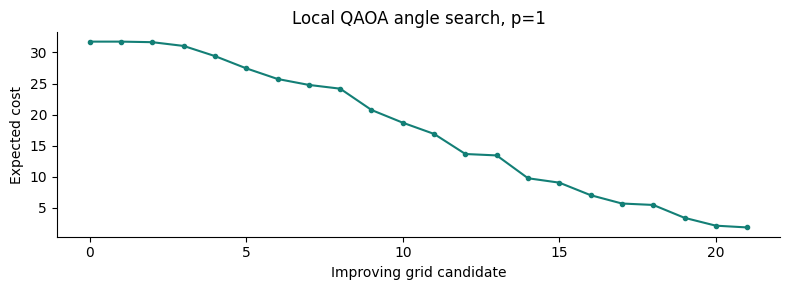

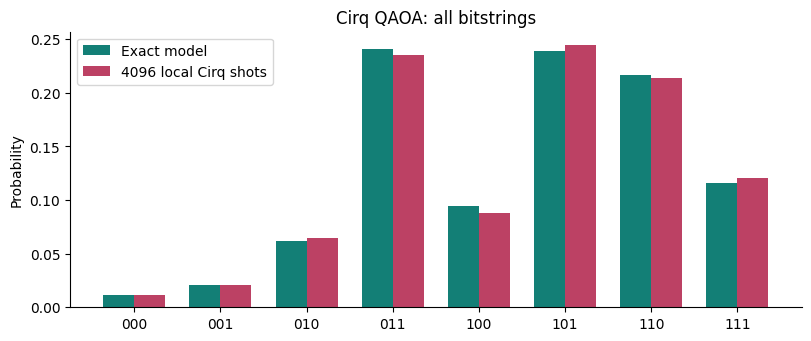

In [3]:
qubits = list(cirq.LineQubit.range(3))
states = np.array([[int(c) for c in f'{i:03b}'] for i in range(8)])
costs = np.array([objective(x) for x in states])
allowed = np.array([feasible(x) for x in states])
assert allowed.any() and allowed[np.argmin(costs)]
exact_best = float(costs[allowed].min())
optimal = allowed & np.isclose(costs, exact_best)
scaled = (costs-costs.min()) / np.ptp(costs)

def qaoa_circuit(gamma, beta):
    return cirq.Circuit(cirq.H.on_each(*qubits),
                        cirq.DiagonalGate((-gamma*scaled).tolist()).on(*qubits),
                        [cirq.rx(2*beta)(q) for q in qubits])

# Exact simulator expectations choose angles; no measured solution is preloaded.
trace, best = [], None
for gamma in np.linspace(0, 2*np.pi, 25):
    for beta in np.linspace(0, np.pi, 25):
        candidate = qaoa_circuit(gamma, beta)
        probs = probabilities(candidate, qubits)
        energy = float(probs @ costs)
        if best is None or energy < best[0]:
            best = (energy, float(gamma), float(beta), candidate, probs)
            trace.append(energy)
energy, gamma, beta, circuit, exact = best

# Independent dense tensor-product formula validates the selected circuit.
rotation = np.array([[np.cos(beta), -1j*np.sin(beta)],
                     [-1j*np.sin(beta), np.cos(beta)]])
mixer = np.kron(np.kron(rotation, rotation), rotation)
reference = np.abs(mixer @ (np.exp(-1j*gamma*scaled)/np.sqrt(8)))**2
assert np.allclose(exact, reference, atol=1e-12)
print('All candidates: bitstring, objective, feasible')
for i, x in enumerate(states):
    print(''.join(map(str, x)), round(float(costs[i]), 6), bool(allowed[i]))
print('Selected angles / expected cost:', gamma, beta, energy)
print('Circuit:', circuit, sep='\n')
plt.figure(figsize=(8, 3))
plt.plot(trace, marker='.', color='#137f76')
plt.xlabel('Improving grid candidate'); plt.ylabel('Expected cost')
plt.title('Local QAOA angle search, p=1'); plt.tight_layout(); plt.show()

counts = measured_counts(circuit, qubits)
sampled = counts/SHOTS
observed_feasible = np.flatnonzero(allowed & (counts > 0))
winner = (int(min(observed_feasible, key=lambda i: costs[i]))
          if len(observed_feasible) else None)
compare_plot([f'{i:03b}' for i in range(8)], exact, sampled, 'Cirq QAOA: all bitstrings')
evidence = {
    'qubits': 3, 'shots': SHOTS, 'counts': counts.tolist(),
    'gamma': gamma, 'beta': beta, 'expected_cost': energy,
    'exact_feasible_optimum': exact_best,
    'best_sampled_feasible': None if winner is None else f'{winner:03b}',
    'sampled_gap': None if winner is None else float(costs[winner]-exact_best),
    'feasible_probability': float(sampled[allowed].sum()),
    'optimal_probability': float(sampled[optimal].sum()),
    'ideal_probability': exact.tolist(),
    'validation': 'Cirq state checked against independent dense QAOA formula',
}
assert counts.sum() == SHOTS and np.isclose(exact.sum(), 1)

assert [f'{i:03b}' for i in np.flatnonzero(allowed)] == ['101']
evidence['sampled_checks'] = [
    {'state': f'{i:03b}', 'count': int(counts[i]),
     'budget_equals_6': bool(budget_cost@x == 6),
     'holdings_equal_2': bool(x.sum() == 2), 'sector_exclusion': bool(x[0]*x[1] == 0)}
    for i, x in enumerate(states) if counts[i] > 0]

## 6. 最终输出与边界 / Evidence & limitations

官方 QAOA 是通用方法；此金融约束模型为我们的扩展。罚系数只对这个已验证的小输入成立；不是任意约束求解器，不包含多期交易、整数松弛或商业优化器。

本次硬件任务为 0。不同 SDK 版本的随机抽样序列可能不同，解析断言仍应成立。

In [4]:
evidence.update({'backend': 'local cirq.Simulator', 'cirq_version': cirq.__version__, 'python': sys.version.split()[0], 'seed': SEED, 'hardware_jobs': 0})
print('EVIDENCE_JSON=' + json.dumps(evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"qubits": 3, "shots": 4096, "counts": [46, 87, 263, 965, 359, 1003, 878, 495], "gamma": 2.0943951023931953, "beta": 2.748893571891069, "expected_cost": 1.8004991812722635, "exact_feasible_optimum": -14.0, "best_sampled_feasible": "101", "sampled_gap": 0.0, "feasible_probability": 0.244873046875, "optimal_probability": 0.244873046875, "ideal_probability": [0.011153064875481726, 0.020572323163636188, 0.0618533181122566, 0.24122157943045228, 0.09412183690029897, 0.23925701139803837, 0.21626322165945341, 0.11555764446038258], "validation": "Cirq state checked against independent dense QAOA formula", "sampled_checks": [{"state": "000", "count": 46, "budget_equals_6": false, "holdings_equal_2": false, "sector_exclusion": true}, {"state": "001", "count": 87, "budget_equals_6": false, "holdings_equal_2": false, "sector_exclusion": true}, {"state": "010", "count": 263, "budget_equals_6": false, "holdings_equal_2": false, "sector_exclusion": true}, {"state": "011", "count": 965, "